# CAMBODIA ACADEMY OF DIGITAL TECHNOLOGY
### Data Visualization Lab: Business Insights from the Cleaned E-commerce Dataset

**Dataset**: `ecommerce_cleaned.csv` (3,660 orders, 1 Jan ? 21 Nov 2024)

Each section answers one group of business questions (Q1?Q15 in `dashboard_guide.md`).
Every chart has a comment block explaining:
- **QUESTION**: the business question it answers
- **CHART**: why this chart type was chosen (and what was rejected)
- **COLOR**: why these colors were used
- **INSIGHT**: what the chart shows

Run the code cells from top to bottom. Charts display inline and are saved to `plots_insights/`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

if sys.stdout.encoding and sys.stdout.encoding.lower() != "utf-8":
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

# Paths with auto-detection
CURRENT_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
candidate_paths = [
    CURRENT_DIR / "ecommerce_cleaned.csv",
    CURRENT_DIR.parent / "datasets" / "ecommerce_cleaned.csv",
    Path("datasets/ecommerce_cleaned.csv"),
]
DATASET_PATH = next((p for p in candidate_paths if p.exists()), candidate_paths[0])
OUTPUT_PLOTS_DIR = CURRENT_DIR / "plots_insights"
OUTPUT_PLOTS_DIR.mkdir(parents=True, exist_ok=True)



## Color system (used by every chart)

We use only THREE working colors, each with one job:
  - BLUE   = "this is the data". Blue is neutral (it doesn't mean good or bad), so it
             doesn't bias the reader, and it stays readable for colorblind viewers.
  - ORANGE = "look here". Used on the ONE bar/point that carries the message.
             Orange is warm and blue is cool, so they separate instantly. Blue/orange is
             the standard colorblind-safe pair (checked: color difference 24.7 under
             red-green colorblindness, well above the 8 needed).
  - GRAY   = "context". Pushes the less important data into the background so the
             highlight stands out. If everything is colorful, nothing stands out.
Rules we follow:
  - No red/green: ~8% of men can't tell them apart, and they imply good/bad judgments.
  - Text is always dark ink, never the series color, so it stays readable.
  - Magnitude (heatmap) uses ONE hue from light to dark: darker = more. Never a rainbow.


In [2]:
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#c3c2b7"
INK = "#0b0b0b"         # titles and values
INK_2 = "#52514e"       # labels and axis text
GRID = "#e1e0d9"        # quiet hairline gridlines
SURFACE = "#fcfcfb"     # off-white background, softer than pure white

# Sequential blue ramp for the heatmap (light = low, dark = high)
SEQ_BLUES = LinearSegmentedColormap.from_list(
    "seq_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#104281"]
)

plt.rcParams.update({
    "font.sans-serif": "Arial",
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
})

rs_fmt = FuncFormatter(lambda x, _: f"Rs {x:,.0f}")
rs_k_fmt = FuncFormatter(lambda x, _: f"Rs {x / 1000:,.0f}k")


def finish(fig, filename, insight):
    """Save the chart, print its insight, and display it."""
    fig.tight_layout()
    fig.savefig(OUTPUT_PLOTS_DIR / filename, dpi=200, facecolor=SURFACE)
    print(f"[{filename}] {insight}")
    plt.show()




## Load data and helper columns


In [3]:
df = pd.read_csv(DATASET_PATH, parse_dates=["Purchase_Date"])
df["Discount_Amount"] = df["Price (Rs.)"] - df["Final_Price(Rs.)"]
df["Month"] = df["Purchase_Date"].dt.to_period("M")
df["Weekday_No"] = df["Purchase_Date"].dt.dayofweek          # Monday = 0
df["Weekday"] = df["Purchase_Date"].dt.day_name().str[:3]
print(f"Loaded {len(df):,} orders from {DATASET_PATH.name}")



Loaded 3,660 orders from ecommerce_cleaned.csv


## Chart 1 – KPI summary (Q1, Q2, Q3)

QUESTION : How much did we earn, how big is a typical order, and how much did discounts cost?
CHART    : Stat tiles (big numbers), not a chart. Each answer is ONE number; a one-bar
           bar chart or a gauge would add ink without adding information.
COLOR    : Numbers in dark ink so they are the first thing read. Only the discount tiles
           use orange, because discount cost is the main problem we want the audience to notice.
INSIGHT  : Rs 757k net revenue; discounts took 18.8% of gross sales.


[chart1_kpi_summary.png] Net revenue Rs 757,278; discounts cost Rs 175,292 (18.8% of gross).


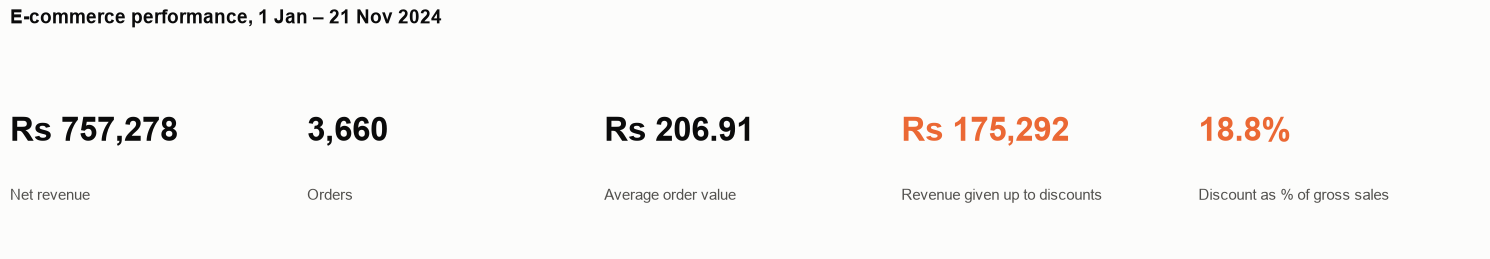

In [4]:
gross = df["Price (Rs.)"].sum()
net = df["Final_Price(Rs.)"].sum()
discount = gross - net
kpis = [
    ("Net revenue", f"Rs {net:,.0f}", INK),
    ("Orders", f"{len(df):,}", INK),
    ("Average order value", f"Rs {net / len(df):,.2f}", INK),
    ("Revenue given up to discounts", f"Rs {discount:,.0f}", ORANGE),
    ("Discount as % of gross sales", f"{discount / gross:.1%}", ORANGE),
]

fig, axes = plt.subplots(1, len(kpis), figsize=(15, 2.6))
for ax, (label, value, color) in zip(axes, kpis):
    ax.axis("off")
    ax.text(0.0, 0.55, value, fontsize=24, fontweight="bold", color=color, transform=ax.transAxes)
    ax.text(0.0, 0.25, label, fontsize=10.5, color=INK_2, transform=ax.transAxes)
fig.suptitle("E-commerce performance, 1 Jan – 21 Nov 2024", x=0.01, ha="left",
             fontsize=14, fontweight="bold", color=INK)
finish(fig, "chart1_kpi_summary.png",
       f"Net revenue Rs {net:,.0f}; discounts cost Rs {discount:,.0f} ({discount / gross:.1%} of gross).")



## Chart 2 – Revenue per day by month (Q4, Q5)

QUESTION : Are sales growing, falling, or stable? Which month is strongest/weakest?
CHART    : Line chart. Time runs left to right and a line lets the eye follow the trend.
           We plot revenue PER DAY, not monthly total, because November only has 21 days;
           a monthly total would show a fake "drop". The y-axis starts at 0 so a ~15% swing
           isn't exaggerated into a crash or boom.
COLOR    : One blue line (single series = one color, no legend needed). Orange marks only
           the best and worst months, the two points the question asks about.
           November uses a hollow marker to signal "incomplete month".
INSIGHT  : Stable at Rs 2,100–2,500/day. Peak April, low June, October strong.


In [ ]:
monthly = df.groupby("Month").agg(revenue=("Final_Price(Rs.)", "sum"),
                                  days=("Purchase_Date", "nunique"))
monthly["per_day"] = monthly["revenue"] / monthly["days"]
labels = monthly.index.strftime("%b")
x = range(len(monthly))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x, monthly["per_day"], color=BLUE, linewidth=2, marker="o", markersize=7)
ax.plot(len(monthly) - 1, monthly["per_day"].iloc[-1], marker="o", markersize=9,
        markerfacecolor=SURFACE, markeredgecolor=BLUE, markeredgewidth=2)  # partial month

for pos, note in [(monthly["per_day"].argmax(), "Highest"), (monthly["per_day"].argmin(), "Lowest")]:
    val = monthly["per_day"].iloc[pos]
    ax.plot(pos, val, marker="o", markersize=10, color=ORANGE, zorder=3)
    ax.annotate(f"{note}: {labels[pos]}\nRs {val:,.0f}/day", (pos, val),
                xytext=(0, 14 if note == "Highest" else -34), textcoords="offset points",
                ha="center", fontsize=9.5, color=INK)
ax.annotate("Nov: 21 days only", (len(monthly) - 1, monthly["per_day"].iloc[-1]),
            xytext=(0, -26), textcoords="offset points", ha="center", fontsize=8.5, color=INK_2)

ax.set_xticks(list(x), labels)
ax.set_ylim(0, 3000)
ax.yaxis.set_major_formatter(rs_fmt)
ax.set_ylabel("Net revenue per day")
ax.set_title("Q4–Q5: Daily revenue is stable all year")
finish(fig, "chart2_revenue_per_day_by_month.png",
       f"Revenue per day ranges Rs {monthly['per_day'].min():,.0f} – Rs {monthly['per_day'].max():,.0f}: stable.")



## Chart 3 – Orders and discount money by discount tier (Q6, Q8)

QUESTION : Do bigger discounts bring more orders? Which tier costs us the most?
CHART    : Two column charts side by side, sharing the same x-axis (discount tier).
           Columns because tiers are ORDERED (0% → 50%), so left-to-right matches the order.
           Two panels instead of a dual-axis chart: orders (count) and discount (Rs) have
           different units, and two y-scales on one plot can invent a fake relationship.
COLOR    : Left panel: all blue. It's one series and the message is "they're all the same".
           Right panel: gray context with the 50% tier in orange, because it is the answer
           to "which tier costs most". Same tier positions in both panels so the eye can
           compare straight down.
INSIGHT  : Orders are flat (412–480 per tier) but discount money climbs steeply; 50% tier costs
           Rs 55k (31.5% of all discount money) and gets FEWER orders than 0% (430 vs 480).


In [ ]:
tiers = df.groupby("Discount (%)").agg(orders=("Category", "size"),
                                       discount=("Discount_Amount", "sum"))
tier_labels = [f"{t}%" for t in tiers.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
bars = ax1.bar(tier_labels, tiers["orders"], color=BLUE, width=0.65)
ax1.bar_label(bars, fmt="{:,.0f}", padding=3, color=INK_2, fontsize=9)
ax1.set_ylim(0, tiers["orders"].max() * 1.2)
ax1.set_xlabel("Discount tier")
ax1.set_ylabel("Number of orders")
ax1.set_title("Q6: Bigger discounts do NOT bring more orders")

colors = [ORANGE if t == 50 else GRAY for t in tiers.index]
bars = ax2.bar(tier_labels, tiers["discount"], color=colors, width=0.65)
share_50 = tiers.loc[50, "discount"] / tiers["discount"].sum()
ax2.bar_label(bars, labels=["" if t != 50 else f"Rs {v / 1000:,.0f}k\n({share_50:.0%} of all discounts)"
                            for t, v in tiers["discount"].items()],
              padding=3, color=INK, fontsize=9)
ax2.set_ylim(0, tiers["discount"].max() * 1.3)
ax2.yaxis.set_major_formatter(rs_k_fmt)
ax2.set_xlabel("Discount tier")
ax2.set_ylabel("Revenue given up")
ax2.set_title("Q8: The 50% tier costs the most")
finish(fig, "chart3_orders_and_discount_by_tier.png",
       f"Orders stay ~{tiers['orders'].mean():,.0f} per tier; 50% tier = {share_50:.1%} of discount money.")



## Chart 4 – Average list price vs price paid by discount tier (Q7)

QUESTION : Do discounts make customers buy more expensive items?
CHART    : Two lines on ONE shared Rs axis. If discounts attracted bigger purchases,
           the list-price line would rise; it stays flat. The shaded gap between the
           lines is the money given up per order, so the cost is visible as an area.
COLOR    : List price in gray (the reference / "what it would have cost"), price paid in
           blue (the actual data). The gap is a light orange wash: orange = the cost we
           want noticed, but kept light so it doesn't overpower the lines. A legend is
           included because there are 2 series, and the lines are also labeled directly.
INSIGHT  : List price stays Rs 243–260 at every tier; only the paid price falls (Rs 255 → 129).


In [ ]:
price = df.groupby("Discount (%)").agg(list_price=("Price (Rs.)", "mean"),
                                       paid=("Final_Price(Rs.)", "mean"))
x = range(len(price))

fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(x, price["paid"], price["list_price"], color=ORANGE, alpha=0.15,
                label="Discount given per order")
ax.plot(x, price["list_price"], color=GRAY, linewidth=2.5, marker="o", markersize=7,
        label="Avg list price (before discount)")
ax.plot(x, price["paid"], color=BLUE, linewidth=2.5, marker="o", markersize=7,
        label="Avg price paid")
ax.text(len(price) - 0.9, price["list_price"].iloc[-1], "List price", va="center", color=INK_2)
ax.text(len(price) - 0.9, price["paid"].iloc[-1], "Price paid", va="center", color=INK_2)

ax.set_xticks(list(x), [f"{t}%" for t in price.index])
ax.set_xlim(-0.3, len(price) - 0.1)
ax.set_ylim(0, 320)
ax.yaxis.set_major_formatter(rs_fmt)
ax.set_xlabel("Discount tier")
ax.set_ylabel("Average per order")
ax.legend(loc="lower left")
ax.set_title("Q7: Customers buy the same-priced items at every discount level")
finish(fig, "chart4_list_vs_paid_price_by_tier.png",
       f"Avg list price {price['list_price'].min():,.0f}–{price['list_price'].max():,.0f} at every tier: discounts don't upsell.")



## Chart 5 – Average discount by category (Q9)

QUESTION : Which category is discounted most heavily?
CHART    : Horizontal bar, sorted. Category names are long and stay readable on the
           y-axis; sorting makes the ranking instant. Axis starts at 0% so the small
           differences (17.9% – 19.6%) are shown honestly, not blown up.
COLOR    : Gray for all, orange only for the top category, the answer to the question.
           Categories have no natural order, so giving each its own color would add
           nothing and make readers hunt for a legend.
INSIGHT  : Home & Kitchen has the highest average discount (19.6%); Clothing the lowest (17.9%).


In [ ]:
cat_disc = df.groupby("Category")["Discount (%)"].mean().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
colors = [ORANGE if c == cat_disc.idxmax() else GRAY for c in cat_disc.index]
bars = ax.barh(cat_disc.index, cat_disc.values, color=colors, height=0.65)
ax.bar_label(bars, fmt="{:.1f}%", padding=4, color=INK, fontsize=9.5)
ax.set_xlim(0, 25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Average discount")
ax.set_title("Q9: Home & Kitchen gets the deepest discounts")
finish(fig, "chart5_avg_discount_by_category.png",
       f"Highest avg discount: {cat_disc.idxmax()} ({cat_disc.max():.1f}%).")



## Chart 6 – Revenue by category (Q10, Q11)

QUESTION : Which category earns the most/least? Do we depend on one category?
CHART    : Horizontal bar sorted largest at the top. A pie/donut is the common choice for
           "share", but 7 slices of 13–15% all look the same and can't be ranked by eye.
           Bars from a zero baseline show both the ranking AND that the gaps are small.
COLOR    : One blue for every bar. This is one measure across unordered categories; bar
           length already shows the value, so extra colors would only add noise.
           Value + share labels at the bar ends (dark ink) so no one needs a tooltip.
INSIGHT  : Clothing leads (15.2%), Electronics last (13.3%); revenue is well balanced.


In [ ]:
cat_rev = df.groupby("Category")["Final_Price(Rs.)"].sum().sort_values()
share = cat_rev / cat_rev.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(cat_rev.index, cat_rev.values, color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"Rs {v / 1000:,.1f}k  ({s:.1%})" for v, s in zip(cat_rev, share)],
             padding=4, color=INK, fontsize=9.5)
ax.set_xlim(0, cat_rev.max() * 1.3)
ax.xaxis.set_major_formatter(rs_k_fmt)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Net revenue")
ax.set_title("Q10–Q11: Revenue is spread evenly across categories")
finish(fig, "chart6_revenue_by_category.png",
       f"Top {cat_rev.idxmax()} ({share.max():.1%}), bottom {cat_rev.idxmin()} ({share.min():.1%}).")



## Chart 7 – Revenue by payment method (Q12)

QUESTION : Which payment method do customers prefer?
CHART    : Horizontal bar, sorted. Five near-equal values (19–21%): a donut would show five
           identical slices; bars show honestly that the methods are almost tied.
COLOR    : Same single blue as Chart 6. Consistent color = same kind of measure
           (revenue by a category), so the audience learns the system once.
INSIGHT  : All methods are within 19–21%; 81% of revenue is paid digitally.


In [ ]:
pay_rev = df.groupby("Payment_Method")["Final_Price(Rs.)"].sum().sort_values()
pay_share = pay_rev / pay_rev.sum()
digital_share = 1 - pay_share["Cash on Delivery"]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(pay_rev.index, pay_rev.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"Rs {v / 1000:,.1f}k  ({s:.1%})" for v, s in zip(pay_rev, pay_share)],
             padding=4, color=INK, fontsize=9.5)
ax.set_xlim(0, pay_rev.max() * 1.3)
ax.xaxis.set_major_formatter(rs_k_fmt)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Net revenue")
ax.set_title(f"Q12: Payment methods are nearly tied ({digital_share:.0%} digital)")
finish(fig, "chart7_revenue_by_payment.png",
       f"Payment shares {pay_share.min():.1%}–{pay_share.max():.1%}; digital = {digital_share:.1%}.")



## Chart 8 – Category × payment heatmap (Q13)

QUESTION : Which category + payment combination sells best and worst?
CHART    : Heatmap (matrix). Two categorical dimensions x one value = 35 cells; a heatmap
           lets the eye find the darkest/lightest cell at once, and the printed numbers
           keep exact values readable. Stacked or grouped bars with 35 pieces would be unreadable.
COLOR    : Sequential single-hue blue, light → dark = low → high. Everyone reads "darker =
           more" without a lesson. Not a rainbow: rainbow colors have no natural order and
           create fake boundaries. Cell text switches to white on dark cells for contrast.
           The best and worst cells are labeled in bold.
INSIGHT  : Best Clothing × Credit Card (Rs 24.8k); worst Electronics × Cash on Delivery (Rs 17.5k).


In [ ]:
matrix = df.pivot_table(index="Category", columns="Payment_Method",
                        values="Final_Price(Rs.)", aggfunc="sum")
vmin, vmax = matrix.values.min(), matrix.values.max()

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(matrix.values, cmap=SEQ_BLUES, aspect="auto", vmin=vmin, vmax=vmax)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        val = matrix.iat[i, j]
        dark = (val - vmin) / (vmax - vmin) > 0.55
        bold = val in (vmin, vmax)
        ax.text(j, i, f"{val / 1000:,.1f}k", ha="center", va="center", fontsize=10,
                color="white" if dark else INK, fontweight="bold" if bold else "normal")
ax.set_xticks(range(matrix.shape[1]), matrix.columns)
ax.set_yticks(range(matrix.shape[0]), matrix.index)
ax.tick_params(length=0)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
cbar = fig.colorbar(im, ax=ax, format=rs_k_fmt, shrink=0.85)
cbar.outline.set_visible(False)
cbar.set_label("Net revenue", color=INK_2)
best, worst = matrix.stack().idxmax(), matrix.stack().idxmin()
ax.set_title(f"Q13: Best {best[0]} × {best[1]}, worst {worst[0]} × {worst[1]}")
finish(fig, "chart8_category_payment_heatmap.png",
       f"Best {best[0]} x {best[1]} (Rs {vmax:,.0f}); worst {worst[0]} x {worst[1]} (Rs {vmin:,.0f}).")



## Chart 9 – Revenue by day of week (Q14, Q15)

QUESTION : Which day is best for sales, and which is weakest?
CHART    : Column chart kept in calendar order (Mon → Sun), NOT sorted by value, because
           weekdays have a natural order people already know. Every weekday appears the
           same number of times (46 or 47) in the data, so totals are a fair comparison.
COLOR    : Gray for normal days, orange for Sunday (best day, the main answer). Saturday
           is called out with a text label instead of a second highlight color, so only
           one thing on the chart shouts.
INSIGHT  : Sunday is best (Rs 115k), Saturday weakest (Rs 99k), about 17% apart.


In [ ]:
dow = (df.groupby(["Weekday_No", "Weekday"])["Final_Price(Rs.)"].sum()
       .reset_index().sort_values("Weekday_No"))
best_day = dow.loc[dow["Final_Price(Rs.)"].idxmax(), "Weekday"]
worst_day = dow.loc[dow["Final_Price(Rs.)"].idxmin(), "Weekday"]

fig, ax = plt.subplots(figsize=(10, 5))
colors = [ORANGE if d == best_day else GRAY for d in dow["Weekday"]]
bars = ax.bar(dow["Weekday"], dow["Final_Price(Rs.)"], color=colors, width=0.65)
ax.bar_label(bars, labels=[f"Rs {v / 1000:,.0f}k" + (" (best)" if d == best_day else
                                                     " (weakest)" if d == worst_day else "")
                           for d, v in zip(dow["Weekday"], dow["Final_Price(Rs.)"])],
             padding=3, color=INK, fontsize=9)
ax.set_ylim(0, dow["Final_Price(Rs.)"].max() * 1.2)
ax.yaxis.set_major_formatter(rs_k_fmt)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Net revenue")
ax.set_title("Q14–Q15: Sunday is the best day to sell, Saturday the weakest")
finish(fig, "chart9_revenue_by_weekday.png",
       f"Best day {best_day}, weakest {worst_day}.")

print(f"\nAll charts saved to: {OUTPUT_PLOTS_DIR}")
